# Euler Maruyama Solver for SDE

In [1]:
%load_ext autoreload
%autoreload 2

## Wiener Process

Simulate one trajectory.

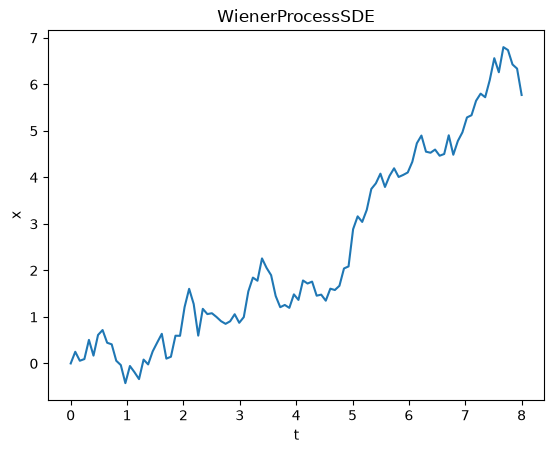

In [2]:
from generative_models.de import WienerProcessSDE, OUProcessSDE, EulerMaruyama
import torch
import matplotlib.pyplot as plt

x0 = torch.Tensor([[0.0]])    # shape (b, d)
t = torch.linspace(0, 8, 100)[None, :]   # shape (b, l)

sde = WienerProcessSDE()
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t[0], x_pred[0])
plt.xlabel("t")
plt.ylabel("x")
plt.title("WienerProcessSDE")
plt.show()

Simulate a set of trajectories.

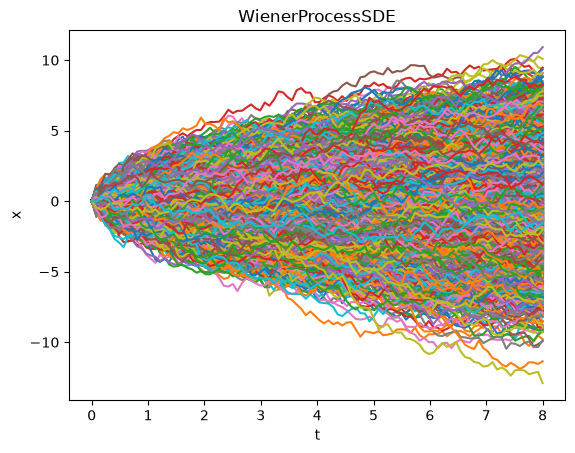

In [3]:
b = 10000
l = 100
t1 = 8

x0 = torch.zeros((b, 1))   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = WienerProcessSDE()
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("WienerProcessSDE")
plt.show()

Draw the distribution of the solution.

/tmp/ipykernel_247565/3582555929.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  p = np.exp(- 0.5 * x**2 / t1) / (np.sqrt(t1) * np.sqrt(2 * np.pi))


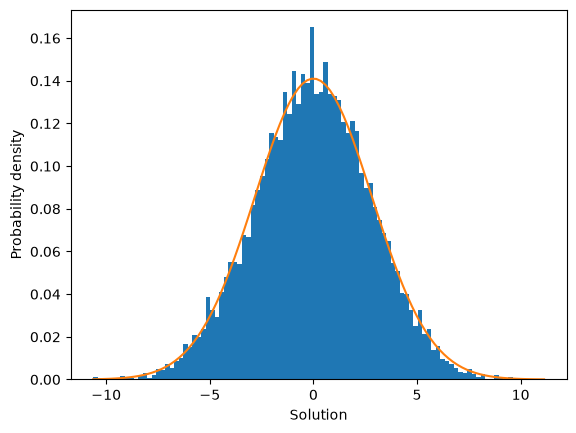

In [4]:
import numpy as np

b = 10000
l = 100
t1 = 8

x0 = torch.zeros((b, 1))   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = WienerProcessSDE()
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=False)   # shape (b, d)

plt.hist(x_pred, bins=100, density=True)

# True distribution of the solution.
x = np.linspace(x_pred.min(), x_pred.max(), 100)
p = np.exp(- 0.5 * x**2 / t1) / (np.sqrt(t1) * np.sqrt(2 * np.pi))

plt.plot(x, p)
plt.xlabel("Solution")
plt.ylabel("Probability density")
plt.show()

## OU Process

Simulate a set of trajectories.

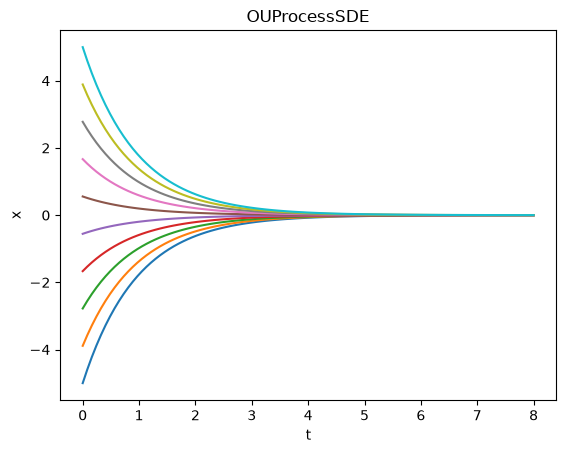

In [5]:
b = 10
l = 100
t1 = 8
theta = 1
sigma = 0.0

x0 = torch.linspace(-5, 5, b)[:, None]   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = OUProcessSDE(theta=theta, sigma=sigma)
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("OUProcessSDE")
plt.show()

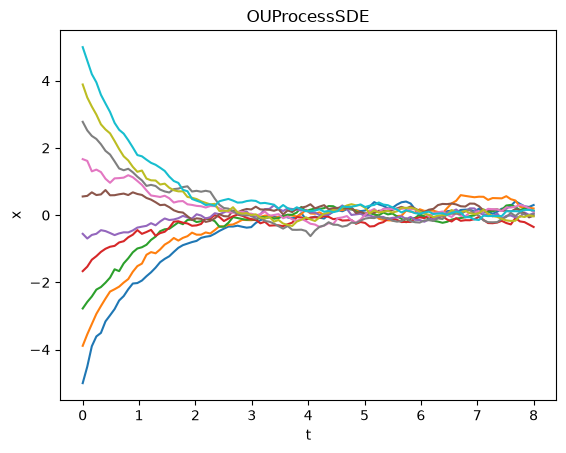

In [6]:
b = 10
l = 100
t1 = 8
theta = 1
sigma = 0.25

x0 = torch.linspace(-5, 5, b)[:, None]   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = OUProcessSDE(theta=theta, sigma=sigma)
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("OUProcessSDE")
plt.show()

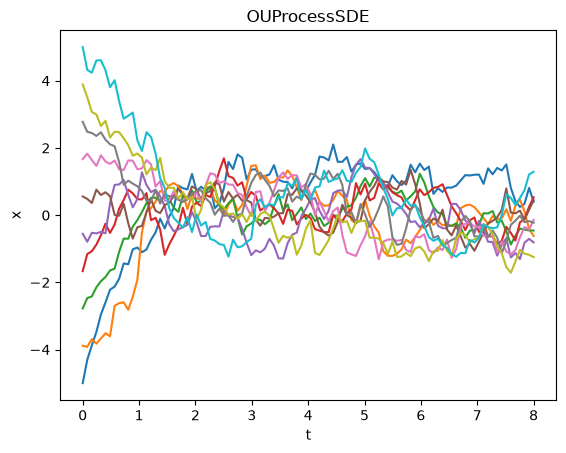

In [7]:
b = 10
l = 100
t1 = 8
theta = 1
sigma = 1

x0 = torch.linspace(-5, 5, b)[:, None]   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = OUProcessSDE(theta=theta, sigma=sigma)
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("OUProcessSDE")
plt.show()

The solution converges to a Gaussian distribution $x \sim \mathcal N(0, \frac{\sigma^2}{2 \theta})$ as $t \rightarrow \infty$, for ANY distribution.

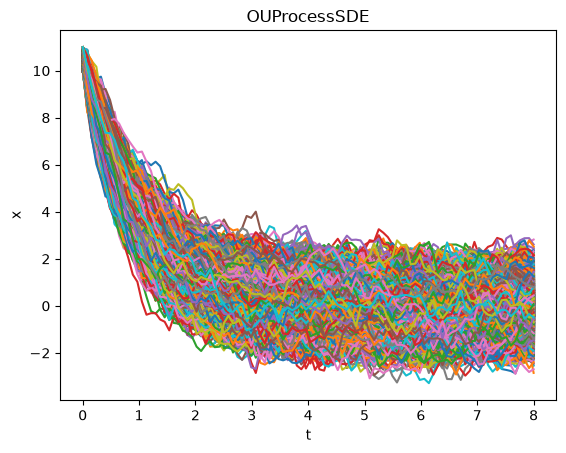

In [8]:
b = 10000
l = 100
t1 = 8
theta = 1
sigma = 1

x0 = torch.linspace(10, 11, b)[:, None]   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = OUProcessSDE(theta=theta, sigma=sigma)
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("OUProcessSDE")
plt.show()

/tmp/ipykernel_247565/1135246775.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  p = np.exp(- 0.5 * x**2 / sigmax_squared) / (np.sqrt(sigmax_squared) * np.sqrt(2 * np.pi))


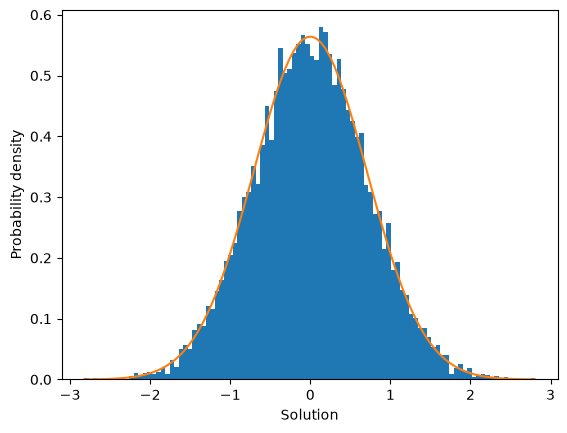

In [9]:
b = 10000
l = 100
t1 = 8
theta = 1
sigma = 1

x0 = torch.linspace(-5, 5, b)[:, None]   # shape (b, d)
t = torch.linspace(0, t1, l)[None, :].expand(b, l)   # shape (b, l)

sde = OUProcessSDE(theta=theta, sigma=sigma)
euler_maruyama = EulerMaruyama(sde=sde)

x_pred = euler_maruyama.simulate_trajectory(x0, t, whole=False)   # shape (b, d)

plt.hist(x_pred, bins=100, density=True)

x = np.linspace(x_pred.min(), x_pred.max(), 100)
sigmax_squared = sigma**2 / (2 * theta)
p = np.exp(- 0.5 * x**2 / sigmax_squared) / (np.sqrt(sigmax_squared) * np.sqrt(2 * np.pi))

plt.plot(x, p)
plt.xlabel("Solution")
plt.ylabel("Probability density")
plt.show()